# Classifying Mirage tactics from minimap video: which model and input?

This report compares classifiers for five CS2 Mirage tactics, using the development matches only. Every score and count is computed from saved runs when the notebook runs. Appendix A7 lists the runs and explains how to reproduce them.

In [1]:
from pathlib import Path

# Every run folder this notebook reads, listed once. Appendix A7 prints which were found;
# a missing folder leaves its table cells as "—".
RUNS = {
    # ResNet images, nested epoch selection
    "img_nested": "runs/tactic-temporal-20261116",  # mean pooling, temporal average pooling
    "img_gru_pooled_nested": "runs/tactic-gru-nested-20261120",  # Compact pooled GRU
    "img_gru_laststate_nested": "runs/tactic-gru-first-nested-20261120",  # Last-state GRU
    "img_gru_compact_laststate_nested": "runs/tactic-gru-middle-nested-20261120",  # Compact last-state GRU
    "img_thirds_unweighted": "runs/tactic-thirds-unweighted-nested-20261120",  # class weights off
    # ResNet images, other-folds epoch selection (Appendix A1)
    "img_other": "runs/tactic-temporal-other-folds-20261119",  # mean, temporal average, Last-state GRU
    "img_gru_compact_laststate_other": "runs/tactic-gru-small-other-folds-20261119",
    "img_gru_pooled_other": "runs/tactic-gru-pooled-other-folds-20261119",
    # Shared clip features: mean pooling, temporal average pooling, GRU
    "clip_nested": "runs/tactic-clipdata-nested-20261120",
    "clip_other": "runs/tactic-clipdata-other-folds-20261120",
    # Shared clip features: TCN and pooled classifier
    "tcn_clip_nested": "runs/tactic-tcn-clipdata-nested-20261120",
    "tcn_clip_other": "runs/tactic-tcn-clipdata-repro-20261119",  # train-only rerun
    # Detector features: TCN and pooled classifier
    "tcn_det_other": "runs/tactic-tcn-repro-20261119",
    "tcn_det_nested": "runs/tactic-tcn-detector-nested-*",  # newest match, if any
    # Shuffled-label checks (the image runs above also hold their own)
    "gru_shuffled": "runs/tactic-gru-shuffled-other-folds-20261120",
    "tcn_clip_shuffled": "runs/tactic-tcn-clipdata-shuffled-20261120",
    # Random-segment control
    "random_segments": "runs/tactic-temporal-random-thirds-20261117",
}

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "stratscout").is_dir() and (p / "AGENTS.md").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the CV-DL repository or its notebooks folder.")


def resolve(path):
    if "*" in path:
        found = sorted(ROOT.glob(path))
        return found[-1] if found else None
    folder = ROOT / path
    return folder if folder.is_dir() else None


runs = {name: resolve(path) for name, path in RUNS.items()}

In [2]:
import csv
import json

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

%matplotlib inline

CLASSES = ["A_DIRECT", "B_DIRECT", "A_SPLIT", "B_SPLIT", "RETAKE"]
SITE = {"A_DIRECT": "A", "A_SPLIT": "A", "B_DIRECT": "B", "B_SPLIT": "B", "RETAKE": "RETAKE"}
MATCH_NAMES = {
    "spirit-falcons-mirage-cologne-major": "Spirit vs Falcons",
    "furia-falcons-mirage-cologne-major-2026": "Furia vs Falcons",
    "mouz-betboom-mirage-iem-bejing-2026": "MOUZ vs BetBoom",
    "aurora-vitality-mirage-esl-pro-league-season-24": "Aurora vs Vitality",
}
MODELS = ["Mean pooling", "Temporal average pooling (3 segments)", "GRU", "TCN", "Pooled classifier"]
INPUTS = ["ResNet images", "Detector features", "Shared clip features"]
# The three GRU designs on ResNet images. In the model comparison the Compact pooled GRU is "GRU".
GRU_NAMES = {"laststate": "Last-state GRU", "compact_laststate": "Compact last-state GRU", "compact_pooled": "Compact pooled GRU"}
DASH = "—"
FONT = "font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px;"
TOLERANCE = 1e-9


def show_table(df, decimals=3):
    """Text columns left, number columns right; scores to three decimals; no index."""
    def is_number(column):
        values = [v for v in df[column] if not (isinstance(v, str) and (v == DASH or v.startswith(DASH)))]
        return bool(values) and all(
            isinstance(v, (int, float, np.number)) and not isinstance(v, bool)
            or isinstance(v, str) and (v[:1].isdigit() or v[:1] in "+-") and "vs" not in v
            for v in values
        )

    numbers = [c for c in df.columns if is_number(c)]
    fmt = {c: (lambda v, d=decimals: v if isinstance(v, str) else f"{v:d}" if isinstance(v, (int, np.integer)) else f"{v:.{d}f}") for c in numbers}
    styles = [
        {"selector": "th", "props": FONT + " font-weight: 600; padding: 4px 10px; border-bottom: 1px solid #999;"},
        {"selector": "td", "props": FONT + " padding: 4px 10px;"},
    ]
    for i, column in enumerate(df.columns):
        styles.append({"selector": f"th.col_heading.col{i}", "props": f"text-align: {'right' if column in numbers else 'left'};"})
    styler = df.style.hide(axis="index").format(fmt).set_table_styles(styles)
    text = [c for c in df.columns if c not in numbers]
    if text:
        styler = styler.set_properties(subset=text, **{"text-align": "left"})
    if numbers:
        styler = styler.set_properties(subset=numbers, **{"text-align": "right"})
    display(styler)


def say(text):
    display(Markdown(text))


def inp(i):
    """An input name inside a sentence: lower case, except ResNet."""
    return i if i.startswith("ResNet") else i.lower()


def fmt(r):
    return f"{r['mean']:.3f} ± {r['sd']:.3f}" if r else DASH


def match_of(clip_id):
    return clip_id.split(".")[0]


def confusion(truth, predicted):
    matrix = np.zeros((5, 5), int)
    np.add.at(matrix, (np.asarray(truth), np.asarray(predicted)), 1)
    return matrix


def f1_per_class(matrix):
    return {c: (2 * matrix[i, i] / (matrix[i].sum() + matrix[:, i].sum()) if matrix[i].sum() + matrix[:, i].sum() else 0.0) for i, c in enumerate(CLASSES)}


VERIFIED = []  # (result, quantity) pairs checked against a saved summary file


def verify(label, quantity, ours, saved):
    """Stop if a value computed here differs from the one the run saved."""
    if saved is None:
        return
    if abs(ours - saved) > TOLERANCE:
        raise ValueError(f"{label}: {quantity} computed {ours!r}, saved {saved!r}")
    VERIFIED.append((label, quantity))


def finish(result):
    """Add the summary numbers: per seed, the mean over the held-out matches; then the
    mean and SD over seeds; per match, the mean over seeds. Pooled scores come from the
    seed ensemble over every clip."""
    pairs, seeds = result["pairs"], result["seeds"]
    matches = sorted(result["clips"])
    per_seed = [float(np.mean([pairs[(m, s)] for m in matches])) for s in seeds]
    pooled = f1_per_class(result["confusion"])
    result.update(
        per_seed=per_seed,
        mean=float(np.mean(per_seed)),
        sd=float(np.std(per_seed)),
        per_match={m: float(np.mean([pairs[(m, s)] for s in seeds])) for m in matches},
        pooled_f1=pooled,
        pooled_macro=float(np.mean(list(pooled.values()))),
    )
    return result


def read_temporal(key, model):
    """One model folder from tactic-temporal (any input, either epoch selection)."""
    folder = runs.get(key)
    if folder is None or not (folder / model / "summary.json").is_file():
        return None
    model_dir = folder / model
    config = json.loads((model_dir / "config.json").read_text(encoding="utf-8"))
    pairs, clips, epochs = {}, {}, {}
    for path in sorted(model_dir.glob("fold-[0-9].json")):
        fold = json.loads(path.read_text(encoding="utf-8"))
        match = match_of(fold["validation_clip_ids"][0])
        clips[match] = sorted(fold["validation_clip_ids"])
        for run in fold["runs"]:
            pairs[(match, run["seed"])] = run["metrics"]["macro_f1"]
            epochs.setdefault(match, []).append(run["evaluation_epoch"])
    with (model_dir / "predictions.csv").open(encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    by_clip = {}
    for row in rows:
        by_clip.setdefault(row["clip_id"], (row["truth"], []))[1].append([float(row[f"p_{c}"]) for c in CLASSES])
    clip_rows = [dict(clip_id=c, truth=CLASSES.index(t), probs=np.mean(p, axis=0)) for c, (t, p) in by_clip.items()]
    result = finish(
        dict(
            source=f"{folder.name}/{model}",
            rule=config["epoch_mode"],
            seeds=list(config["settings"]["seeds"]),
            pairs=pairs,
            clips=clips,
            epochs=epochs,
            clip_rows=clip_rows,
            confusion=confusion([r["truth"] for r in clip_rows], [int(r["probs"].argmax()) for r in clip_rows]),
            config=config,
        )
    )
    saved = json.loads((folder / "summary.json").read_text(encoding="utf-8"))["models"][model]
    verify(result["source"], "mean", result["mean"], saved["macro_f1"]["mean"])
    verify(result["source"], "seed SD", result["sd"], saved["macro_f1"]["std"])
    verify(result["source"], "seed-ensemble macro-F1", result["pooled_macro"], (saved.get("seed_ensemble") or {}).get("macro_f1"))
    return result


def read_tcn_nested(key, kind):
    """scripts/nested_tcn.py output: one JSON per model and outer match."""
    folder = runs.get(key)
    parts = sorted(folder.glob(f"{kind}-*.json")) if folder else []
    if len(parts) != 4:
        return None
    pairs, clips, epochs, clip_rows, config = {}, {}, {}, [], None
    for path in parts:
        part = json.loads(path.read_text(encoding="utf-8"))
        match = part["outer_match"]
        clips[match] = sorted(part["clip_ids"])
        epochs[match] = [part["chosen_epochs"]] * len(part["seeds"])
        for s in part["seeds"]:
            pairs[(match, s["seed"])] = s["macro_f1"]
        mean_probs = np.mean([s["probs"] for s in part["seeds"]], axis=0)
        clip_rows += [dict(clip_id=c, truth=t, probs=p) for c, t, p in zip(part["clip_ids"], part["y"], mean_probs)]
        config = part["config"]
    result = finish(
        dict(
            source=f"{folder.name}/{kind}-*.json",
            rule="nested",
            seeds=list(config["seeds"]),
            pairs=pairs,
            clips=clips,
            epochs=epochs,
            clip_rows=clip_rows,
            confusion=confusion([r["truth"] for r in clip_rows], [int(r["probs"].argmax()) for r in clip_rows]),
            config=config,
        )
    )
    summary = folder / "summary.json"
    if summary.is_file():
        saved = json.loads(summary.read_text(encoding="utf-8"))["models"][kind]
        verify(result["source"], "mean", result["mean"], saved["nested_macro_f1_mean_over_seeds"])
        verify(result["source"], "seed SD", result["sd"], saved["nested_macro_f1_seed_sd"])
        verify(result["source"], "seed-ensemble macro-F1", result["pooled_macro"], saved["ensemble_macro_f1"])
        for m, value in saved["per_match_macro_f1"].items():
            verify(result["source"], f"{m} macro-F1", result["per_match"][m], value)
    return result


def read_tcn_other(key, kind):
    """train-tactics cross-validation (other-folds epoch selection). Test results are never read."""
    folder = runs.get(key)
    if folder is None or not (folder / "report.json").is_file():
        return None
    report = json.loads((folder / "report.json").read_text(encoding="utf-8"))
    if kind not in report["models"]:
        return None
    cv = report["models"][kind]["cv"]
    pairs = {}
    for run in report["models"][kind]["cv_runs"]:
        epoch = cv["cross_fold_epochs"][run["held_out"]]
        pairs[(run["held_out"], run["seed"])] = dict(run["history"])[epoch]
    with (folder / "cv_predictions.csv").open(encoding="utf-8") as stream:
        rows = [r for r in csv.DictReader(stream) if r["model"] == kind]
    clips = {}
    for row in rows:
        clips.setdefault(row["match"], []).append(row["clip_id"])
    result = finish(
        dict(
            source=f"{folder.name} ({kind})",
            rule="other-folds",
            seeds=list(report["config"]["seeds"]),
            pairs=pairs,
            clips={m: sorted(v) for m, v in clips.items()},
            epochs={m: [e] * len(report["config"]["seeds"]) for m, e in cv["cross_fold_epochs"].items()},
            clip_rows=[dict(clip_id=r["clip_id"], truth=CLASSES.index(r["true"]), probs=np.array([float(r[f"p_{c}"]) for c in CLASSES])) for r in rows],
            confusion=np.array(cv["pooled"]["ensemble"]["confusion"]),
            config=report["config"],
        )
    )
    verify(result["source"], "mean", result["mean"], cv["cross_fold_macro_f1"])
    for m, value in cv["per_fold_macro_f1"].items():
        verify(result["source"], f"{m} macro-F1", result["per_match"][m], value)
    verify(result["source"], "seed-ensemble macro-F1", result["pooled_macro"], cv["pooled"]["ensemble"]["macro_f1"])
    return result


# Main results: (model, input, epoch selection) -> result. Missing runs are left out.
LOADERS = {
    ("Mean pooling", "ResNet images", "nested"): lambda: read_temporal("img_nested", "mean"),
    ("Temporal average pooling (3 segments)", "ResNet images", "nested"): lambda: read_temporal("img_nested", "thirds"),
    ("GRU", "ResNet images", "nested"): lambda: read_temporal("img_gru_pooled_nested", "gru"),
    ("Mean pooling", "ResNet images", "other-folds"): lambda: read_temporal("img_other", "mean"),
    ("Temporal average pooling (3 segments)", "ResNet images", "other-folds"): lambda: read_temporal("img_other", "thirds"),
    ("GRU", "ResNet images", "other-folds"): lambda: read_temporal("img_gru_pooled_other", "gru"),
    ("Mean pooling", "Shared clip features", "nested"): lambda: read_temporal("clip_nested", "mean"),
    ("Temporal average pooling (3 segments)", "Shared clip features", "nested"): lambda: read_temporal("clip_nested", "thirds"),
    ("GRU", "Shared clip features", "nested"): lambda: read_temporal("clip_nested", "gru"),
    ("Mean pooling", "Shared clip features", "other-folds"): lambda: read_temporal("clip_other", "mean"),
    ("Temporal average pooling (3 segments)", "Shared clip features", "other-folds"): lambda: read_temporal("clip_other", "thirds"),
    ("GRU", "Shared clip features", "other-folds"): lambda: read_temporal("clip_other", "gru"),
    ("TCN", "Shared clip features", "nested"): lambda: read_tcn_nested("tcn_clip_nested", "tcn"),
    ("Pooled classifier", "Shared clip features", "nested"): lambda: read_tcn_nested("tcn_clip_nested", "control"),
    ("TCN", "Shared clip features", "other-folds"): lambda: read_tcn_other("tcn_clip_other", "tcn"),
    ("Pooled classifier", "Shared clip features", "other-folds"): lambda: read_tcn_other("tcn_clip_other", "control"),
    ("TCN", "Detector features", "nested"): lambda: read_tcn_nested("tcn_det_nested", "tcn"),
    ("Pooled classifier", "Detector features", "nested"): lambda: read_tcn_nested("tcn_det_nested", "control"),
    ("TCN", "Detector features", "other-folds"): lambda: read_tcn_other("tcn_det_other", "tcn"),
    ("Pooled classifier", "Detector features", "other-folds"): lambda: read_tcn_other("tcn_det_other", "control"),
}
# The three GRU designs on ResNet images, both epoch selections.
GRU_VERSIONS = {
    "laststate": ("img_gru_laststate_nested", "img_other"),
    "compact_laststate": ("img_gru_compact_laststate_nested", "img_gru_compact_laststate_other"),
    "compact_pooled": ("img_gru_pooled_nested", "img_gru_pooled_other"),
}
results = {key: load() for key, load in LOADERS.items()}
results = {key: value for key, value in results.items() if value is not None}
gru_versions = {
    version: {"nested": read_temporal(nested, "gru"), "other-folds": read_temporal(other, "gru")}
    for version, (nested, other) in GRU_VERSIONS.items()
}
unweighted = read_temporal("img_thirds_unweighted", "thirds")
random_segments = read_temporal("random_segments", "random-thirds")

# The same clips, folds, seeds and epoch selection for every result, or stop here.
everything = list(results.items()) + [
    ((GRU_NAMES[v], "ResNet images", rule), r) for v, d in gru_versions.items() for rule, r in d.items() if r
] + [
    (("Temporal average pooling, class weights off", "ResNet images", "nested"), unweighted),
    (("Random-segment control", "ResNet images", "nested"), random_segments),
]
everything = [(k, r) for k, r in everything if r is not None]
reference = results[("Mean pooling", "ResNet images", "nested")]["clips"]
for (model, inputs, rule), r in everything:
    if r["clips"] != reference:
        raise ValueError(f"{model} on {inputs} ({rule}) uses other clips or folds than the reference")
    if r["seeds"] != [0, 1, 2]:
        raise ValueError(f"{model} on {inputs} ({rule}) uses seeds {r['seeds']}")
    if r["rule"] != rule:
        raise ValueError(f"{model} on {inputs}: saved epoch selection {r['rule']!r}, expected {rule!r}")
N_CLIPS = sum(len(v) for v in reference.values())
MATCHES = list(MATCH_NAMES)
N_SEEDS = len(results[("Mean pooling", "ResNet images", "nested")]["seeds"])
nested = {(m, i): r for (m, i, rule), r in results.items() if rule == "nested"}
best_key = max(nested, key=lambda k: nested[k]["mean"])

## What did we find?

In [3]:
best_model, best_input = best_key
best = nested[best_key]
both = [m for m in MODELS if (m, "ResNet images") in nested and (m, "Shared clip features") in nested]
changes = {m: nested[(m, "Shared clip features")]["mean"] - nested[(m, "ResNet images")]["mean"] for m in both}
clip_models = {m: nested[(m, "Shared clip features")] for m in MODELS if (m, "Shared clip features") in nested}
clip_spread = max(r["mean"] for r in clip_models.values()) - min(r["mean"] for r in clip_models.values())
if both and min(changes.values()) > clip_spread:
    finding = (
        f"**The input mattered more than the model.** With the same model, shared clip features instead of ResNet "
        f"images raised nested macro-F1 by {min(changes.values()):+.3f} to {max(changes.values()):+.3f} "
        f"({len(both)} models run on both). Across the {len(clip_models)} models on shared clip features, "
        f"scores differ by at most {clip_spread:.3f}."
    )
elif both:
    finding = (
        f"With the same model, shared clip features instead of ResNet images changed nested macro-F1 by "
        f"{min(changes.values()):+.3f} to {max(changes.values()):+.3f} ({len(both)} models); across models on shared "
        f"clip features, scores differ by up to {clip_spread:.3f}."
    )
else:
    finding = "No model has nested runs on both ResNet images and shared clip features yet."
say(
    f"- **Task:** name the tactic of {N_CLIPS} hand-cut Mirage clips from {len(MATCHES)} development matches "
    f"({len(CLASSES)} classes), training on all but one match and testing on the match left out.\n"
    f"- **Strongest completed nested result:** {best_model} on {inp(best_input)}, nested macro-F1 {fmt(best)} "
    f"(mean over {len(reference)} held-out matches × {N_SEEDS} seeds; ± is the SD over seeds).\n"
    f"- **Main comparison finding:** {finding}"
)

- **Task:** name the tactic of 82 hand-cut Mirage clips from 4 development matches (5 classes), training on all but one match and testing on the match left out.
- **Strongest completed nested result:** TCN on shared clip features, nested macro-F1 0.849 ± 0.021 (mean over 4 held-out matches × 3 seeds; ± is the SD over seeds).
- **Main comparison finding:** **The input mattered more than the model.** With the same model, shared clip features instead of ResNet images raised nested macro-F1 by +0.143 to +0.278 (3 models run on both). Across the 5 models on shared clip features, scores differ by at most 0.086.

## 1. What is the task, and what data do the models learn from?

Each clip is one attack or one retake from a professional CS2 match on Mirage, seen through the spectator minimap. A model must name its tactic:

- **A_DIRECT:** Ts attack A through ramp and/or palace, without a coordinated push from mid through connector.
- **B_DIRECT:** Ts attack B through apartments, without a coordinated push from mid through short.
- **A_SPLIT:** an attack through ramp and/or palace combined with one from mid through connector, in the same engagement.
- **B_SPLIT:** an attack through apartments combined with one from mid through short, in the same engagement.
- **RETAKE:** after a plant, CTs try to win the site back (success not required).

**Split or direct?** Both end on the same site; the difference is a second group. If the Ts hit A only from ramp and palace, the clip is A_DIRECT. If another group pushes from mid through connector onto A at the same time, it is A_SPLIT.

**How the clips were made.** Match demos were replayed in CS2 and the minimap was screen-recorded ([recording guide](../docs/recording-setup.md)). A labeller marked the start and end of each attack or retake on the video and chose its class ([labelling guide](../docs/labelling-guide.md)). A second person reviewed the labels, and only reviewed clips were exported ([tactic definitions](../docs/tactic-definitions.md)). The test matches are not read by this notebook.

In [4]:
fold_files = sorted((runs["img_nested"] / "mean").glob("fold-[0-9].json"))
by_match = {}
for path in fold_files:
    fold = json.loads(path.read_text(encoding="utf-8"))
    by_match[match_of(fold["validation_clip_ids"][0])] = fold["validation_counts"]
table = pd.DataFrame(
    [[c] + [by_match[m][c] for m in MATCHES] + [sum(by_match[m][c] for m in MATCHES)] for c in CLASSES]
    + [["All classes"] + [sum(by_match[m].values()) for m in MATCHES] + [N_CLIPS]],
    columns=["Class"] + [MATCH_NAMES[m] for m in MATCHES] + ["Total"],
)
show_table(table)
totals = {c: sum(by_match[m][c] for m in MATCHES) for c in CLASSES}
small, large = min(totals, key=totals.get), max(totals, key=totals.get)
always = np.zeros((5, 5), int)
for i, c in enumerate(CLASSES):
    always[i, CLASSES.index(large)] = totals[c]
excluded = results[("Mean pooling", "ResNet images", "nested")]["config"].get("excluded_clip_ids", [])
say(
    f"**Answer.** The data are {N_CLIPS} labelled clips from {len(MATCHES)} development matches. Classes are uneven: "
    f"{small} has {totals[small]} clips and {large} has {totals[large]}. A model that always answered {large} would be "
    f"right on {totals[large] / N_CLIPS:.0%} of clips, yet its macro-F1 would be only {np.mean(list(f1_per_class(always).values())):.3f}, "
    f"because the other {len(CLASSES) - 1} classes score F1 = 0. Macro-F1 (the mean of the {len(CLASSES)} class F1 scores) is "
    "therefore the main score: every tactic counts equally, however many clips it has."
    + (
        " Left out as uncertain: "
        + ", ".join(f"{MATCH_NAMES[match_of(c)]} clip {c.split('.')[-1]}" for c in excluded)
        + "."
        if excluded
        else ""
    )
)

Class,Spirit vs Falcons,Furia vs Falcons,MOUZ vs BetBoom,Aurora vs Vitality,Total
A_DIRECT,3,5,4,3,15
B_DIRECT,11,5,5,3,24
A_SPLIT,2,6,1,5,14
B_SPLIT,2,2,3,2,9
RETAKE,3,4,7,6,20
All classes,21,22,20,19,82


**Answer.** The data are 82 labelled clips from 4 development matches. Classes are uneven: B_SPLIT has 9 clips and B_DIRECT has 24. A model that always answered B_DIRECT would be right on 29% of clips, yet its macro-F1 would be only 0.091, because the other 4 classes score F1 = 0. Macro-F1 (the mean of the 5 class F1 scores) is therefore the main score: every tactic counts equally, however many clips it has. Left out as uncertain: Spirit vs Falcons clip s005.

## 2. How does a clip become a prediction, and how is a model scored?

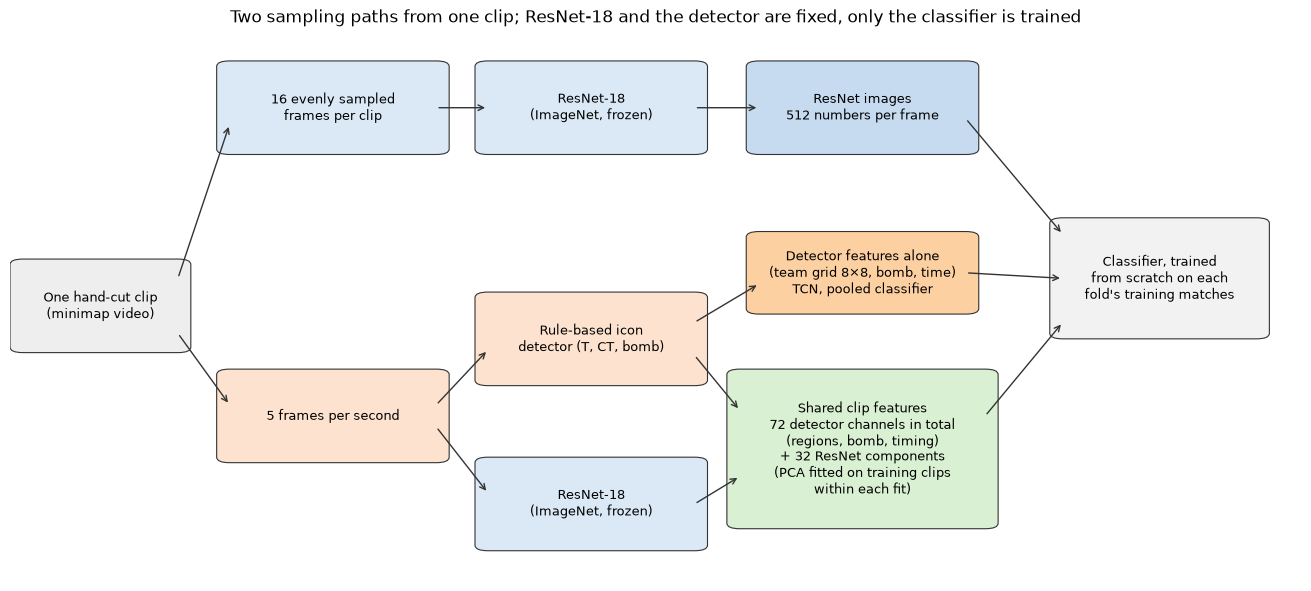

**Answer.** Two sampling paths start from the same clip. **Image models** take 16 evenly sampled frames per clip and pass each through a frozen ImageNet ResNet-18 (512 numbers per frame). **Shared clip features** use 5 frames per second: on each of those frames a rule-based detector gives 72 detector channels in total (regions, bomb, timing), and the same frozen ResNet-18 gives 512 numbers, compressed to 32 ResNet components by a PCA fitted on the training clips within each fit. Shared clip features are an input representation computed from the same clips; nothing is pretrained on them, and every classifier trains from scratch on each fold's three training matches.

In [5]:
image_config = results[("Mean pooling", "ResNet images", "nested")]["config"]
n_frames = image_config["settings"]["n_frames"]
resnet_width = (image_config["trainable_parameters"] - len(CLASSES)) // len(CLASSES)  # a linear head on the frame mean
clip_summary = json.loads((runs["clip_nested"] / "summary.json").read_text(encoding="utf-8"))
detector_channels = clip_summary["clip_data"]["detector_channels"]
pcs = clip_summary["clip_data"]["resnet_pcs"]
rows_per_clip = {s["clip_id"]: s["rows"] for s in json.loads((runs["clip_nested"] / "samples.json").read_text(encoding="utf-8"))}
with (runs["clip_nested"] / "input-manifest.csv").open(encoding="utf-8-sig") as stream:
    durations = {r["clip_id"]: float(r["duration_s"]) for r in csv.DictReader(stream)}
rate = float(np.median([rows_per_clip[c] / durations[c] for c in rows_per_clip]))
grid = results[("TCN", "Detector features", "other-folds")]["config"]["grid"] if ("TCN", "Detector features", "other-folds") in results else None

fig, ax = plt.subplots(figsize=(13, 5.8), layout="constrained")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")


def box(x, y, text, colour, width=0.16, height=0.15):
    ax.add_patch(FancyBboxPatch((x - width / 2, y - height / 2), width, height, boxstyle="round,pad=0.01", facecolor=colour, edgecolor="#333333", linewidth=0.8))
    ax.text(x, y, text, ha="center", va="center", fontsize=9)


def arrow(a, b, style="-"):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="#333333", linewidth=1, linestyle=style))


box(0.07, 0.5, "One hand-cut clip\n(minimap video)", "#eeeeee", width=0.12)
box(0.25, 0.86, f"{n_frames} evenly sampled\nframes per clip", "#dbe9f6")
box(0.45, 0.86, "ResNet-18\n(ImageNet, frozen)", "#dbe9f6")
box(0.66, 0.86, f"ResNet images\n{resnet_width} numbers per frame", "#c6dbef")
box(0.25, 0.30, f"{rate:.0f} frames per second", "#fde3cf")
box(0.45, 0.44, "Rule-based icon\ndetector (T, CT, bomb)", "#fde3cf")
box(0.45, 0.14, "ResNet-18\n(ImageNet, frozen)", "#dbe9f6")
box(0.66, 0.56, "Detector features alone\n" + (f"(team grid {grid}×{grid}, bomb, time)\n" if grid else "") + "TCN, pooled classifier", "#fdd0a2", height=0.13)
box(
    0.66, 0.24,
    f"Shared clip features\n{detector_channels} detector channels in total\n(regions, bomb, timing)\n+ {pcs} ResNet components\n(PCA fitted on training clips\nwithin each fit)",
    "#d9f0d3", width=0.19, height=0.27,
)
box(0.89, 0.55, "Classifier, trained\nfrom scratch on each\nfold's training matches", "#f2f2f2", width=0.15, height=0.2)
arrow((0.13, 0.55), (0.17, 0.83))
arrow((0.13, 0.45), (0.17, 0.32))
arrow((0.33, 0.86), (0.37, 0.86))
arrow((0.53, 0.86), (0.58, 0.86))
arrow((0.33, 0.32), (0.37, 0.42))
arrow((0.33, 0.28), (0.37, 0.16))
arrow((0.53, 0.47), (0.58, 0.54))
arrow((0.53, 0.41), (0.565, 0.31))
arrow((0.53, 0.14), (0.565, 0.19))
arrow((0.74, 0.84), (0.815, 0.63))
arrow((0.74, 0.56), (0.815, 0.55))
arrow((0.755, 0.30), (0.815, 0.47))
ax.set_title("Two sampling paths from one clip; ResNet-18 and the detector are fixed, only the classifier is trained", fontsize=12)
plt.show()
say(
    f"**Answer.** Two sampling paths start from the same clip. **Image models** take {n_frames} evenly sampled frames per clip "
    f"and pass each through a frozen ImageNet ResNet-18 ({resnet_width} numbers per frame). **Shared clip features** use "
    f"{rate:.0f} frames per second: on each of those frames a rule-based detector gives {detector_channels} detector channels in "
    f"total (regions, bomb, timing), and the same frozen ResNet-18 gives {resnet_width} numbers, compressed to {pcs} ResNet "
    "components by a PCA fitted on the training clips within each fit. Shared clip features are an input representation "
    "computed from the same clips; nothing is pretrained on them, and every classifier trains from scratch on each fold's "
    "three training matches."
)

In [6]:
n_matches = len(reference)
say(
    "**Design decisions.**\n\n"
    "| Decision | Choice | Why |\n|---|---|---|\n"
    f"| Image features | Frozen ImageNet ResNet-18 | Freezing limits the parameters learned from {N_CLIPS} clips to the small classifier on top. |\n"
    "| Player positions | Rule-based minimap icon detector | There are no labelled positions to train a detector on; its positions were checked against the true positions in the match demos ([detector check](../docs/detector-check.md)). |\n"
    f"| Data split | Leave one match out ({n_matches} folds) | Clips from one match are correlated (same teams, same recording), so they must not be split between training and scoring. |\n"
    "| Epoch choice | Nested epoch selection | The scored match never influences the number of training epochs. |\n"
    f"| Training noise | {N_SEEDS} seeds per held-out match | Shows how much a score moves with the random start alone. |\n"
    "| Main score | Macro-F1 | Classes are uneven; every tactic counts equally. |\n"
    "| Loss | Class-weighted cross-entropy | Small classes count as much as large ones during training. |\n\n"
    f"A model's score is the mean over the {n_matches} held-out matches and {N_SEEDS} seeds; ± is the SD over seeds of "
    "each seed's mean over matches."
)

**Design decisions.**

| Decision | Choice | Why |
|---|---|---|
| Image features | Frozen ImageNet ResNet-18 | Freezing limits the parameters learned from 82 clips to the small classifier on top. |
| Player positions | Rule-based minimap icon detector | There are no labelled positions to train a detector on; its positions were checked against the true positions in the match demos ([detector check](../docs/detector-check.md)). |
| Data split | Leave one match out (4 folds) | Clips from one match are correlated (same teams, same recording), so they must not be split between training and scoring. |
| Epoch choice | Nested epoch selection | The scored match never influences the number of training epochs. |
| Training noise | 3 seeds per held-out match | Shows how much a score moves with the random start alone. |
| Main score | Macro-F1 | Classes are uneven; every tactic counts equally. |
| Loss | Class-weighted cross-entropy | Small classes count as much as large ones during training. |

A model's score is the mean over the 4 held-out matches and 3 seeds; ± is the SD over seeds of each seed's mean over matches.

## 3. How were the models developed and trained?

**The five model families.**

- **Mean pooling:** average the clip's frames (or rows), then a linear classifier.
- **Temporal average pooling (3 segments):** average the early, middle and late thirds separately and join them, then a linear classifier; this keeps coarse order.
- **GRU:** a small recurrent network reads the frames in order, with their elapsed time, and a linear classifier reads its memory.
- **TCN:** a residual temporal convolution network with growing dilation over the rows.
- **Pooled classifier:** the TCN's control. It takes the same rows, averaged and max-pooled over the clip before a small network, so step order cannot matter.

**Loss.** Class-weighted cross-entropy: each class is weighted by the inverse of its share of the training clips ([tactic_training.py, `fit_classifier`](../stratscout/tactic_training.py#L191)). The TCN and pooled classifier add label smoothing ([tactic_tcn.py, `train_model`](../stratscout/tactic_tcn.py#L243)).

**Optimiser.** AdamW on the full training batch for the pooling models and the GRU ([tactic_training.py](../stratscout/tactic_training.py#L188)). The TCN and pooled classifier use AdamW on mini-batches with a linear warm-up ([tactic_tcn.py](../stratscout/tactic_tcn.py#L237)).

**Nested epoch selection.** For each held-out match, each of its training matches is left out in turn, and the epoch with the highest mean macro-F1 on those inner matches is chosen. The model is then refitted on all of its training matches for exactly that many epochs, and the held-out match is scored once ([tactic_training.py, `nested_epoch`](../stratscout/tactic_training.py#L260); for the TCN, [scripts/nested_tcn.py](../scripts/nested_tcn.py)). Appendix A5 has every setting.

### Which GRU design works best?

In [7]:
designs = {v: gru_versions[v]["nested"] for v in GRU_NAMES}
if all(designs.values()):
    compact = designs["compact_laststate"]["config"]["temporal"]
    x, y, z = (designs[v]["mean"] for v in GRU_NAMES)
    say(
        "A GRU updates a memory as it reads each frame. On image features, the Last-state GRU classified the clip from its "
        f"final memory and scored {x:.3f} nested macro-F1. The Compact last-state GRU made the network compact (frames "
        f"squeezed to {compact['projection']} numbers, a memory of {compact['hidden']}) and added dropout; this moved the "
        f"score to {y:.3f}. The Compact pooled GRU kept that compact recurrent network and took the average and maximum of "
        f"each memory value across real frames; this {'raised' if z > y else 'changed'} the score to {z:.3f}."
        + (" We therefore selected the pooled readout." if z == max(x, y, z) else "")
    )
    changed = {
        "laststate": "Starting design; the classifier reads the final memory",
        "compact_laststate": "Smaller network with dropout; the classifier still reads the final memory",
        "compact_pooled": "Same compact network; the classifier reads the average and maximum memory values across frames",
    }
    show_table(
        pd.DataFrame(
            [[GRU_NAMES[v], changed[v], fmt(designs[v])] for v in GRU_NAMES],
            columns=["GRU design", "What changed", "Nested macro-F1"],
        )
    )
    say("Sizes, parameter counts and other-folds scores are in Appendix A6.")
else:
    say(f"{DASH} At least one of the three nested GRU runs is missing (Appendix A7).")

A GRU updates a memory as it reads each frame. On image features, the Last-state GRU classified the clip from its final memory and scored 0.345 nested macro-F1. The Compact last-state GRU made the network compact (frames squeezed to 8 numbers, a memory of 16) and added dropout; this moved the score to 0.327. The Compact pooled GRU kept that compact recurrent network and took the average and maximum of each memory value across real frames; this raised the score to 0.600. We therefore selected the pooled readout.

GRU design,What changed,Nested macro-F1
Last-state GRU,Starting design; the classifier reads the final memory,0.345 ± 0.008
Compact last-state GRU,Smaller network with dropout; the classifier still reads the final memory,0.327 ± 0.004
Compact pooled GRU,Same compact network; the classifier reads the average and maximum memory values across frames,0.600 ± 0.028


Sizes, parameter counts and other-folds scores are in Appendix A6.

### Do the GRUs overfit?

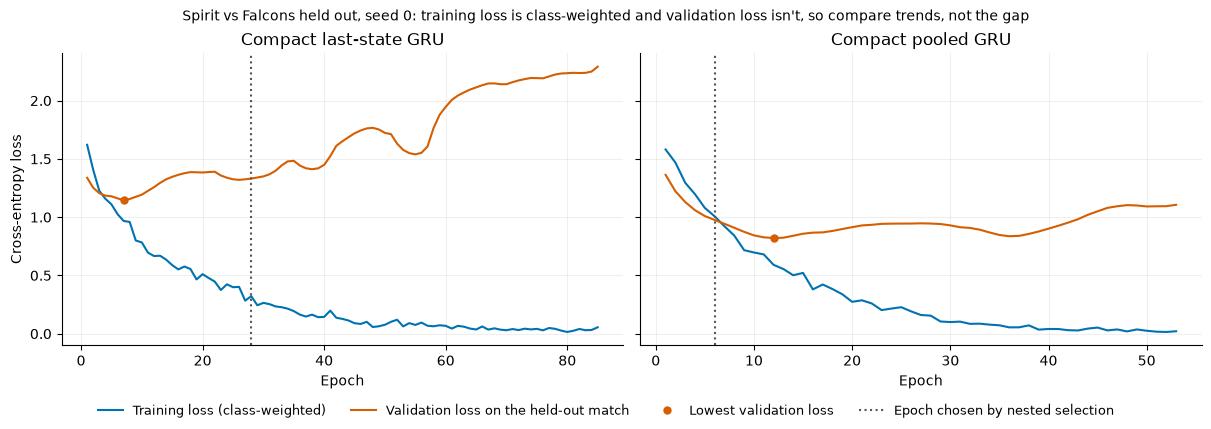

**Compact last-state GRU:** validation loss was lowest at epoch 7 (1.15) and ended at 2.29 at epoch 85, while training loss fell from 0.97 to 0.055. Training loss kept falling while validation loss rose after epoch 7: the network overfits.

**Compact pooled GRU:** validation loss was lowest at epoch 12 (0.82) and ended at 1.11 at epoch 53, while training loss fell from 0.59 to 0.021. Training loss kept falling while validation loss rose after epoch 12, but the rise is small: across all 12 held-out-match-and-seed curves, its validation loss rose on average 0.14 above its minimum over the first 31 epochs (the shortest curve), against 0.49 for the Compact last-state GRU and 1.10 for the Last-state GRU. This is mild overfitting.

The larger Last-state GRU overfits most strongly: over the first 31 epochs its validation loss rose on average 1.10 above its minimum, and its training loss fell to 0.004.

The chosen epochs (dotted lines, 28 and 6) need not match the lowest point of these curves: epochs are chosen by macro-F1, not loss, and from the three training matches, not from the held-out curve shown. The curves come from a fit scored on the held-out match every epoch; they are a diagnostic and choose nothing.

In [8]:
CURVE_FOLD, CURVE_SEED = 1, 0  # the first held-out match and the first seed
SHOWN = ("compact_laststate", "compact_pooled")


def curve(version, fold=CURVE_FOLD, seed=CURVE_SEED):
    """The fit on the training matches, scored on the held-out match every epoch (a diagnostic; it chooses nothing)."""
    folder = runs.get(GRU_VERSIONS[version][0])
    path = folder / "gru" / f"fold-{fold}-seed-{seed}-optimistic-history.json" if folder else None
    if path is None or not path.is_file():
        return None
    history = json.loads(path.read_text(encoding="utf-8"))
    fold_json = json.loads((folder / "gru" / f"fold-{fold}.json").read_text(encoding="utf-8"))
    chosen = next(run["evaluation_epoch"] for run in fold_json["runs"] if run["seed"] == seed)
    train = np.array([h["train_loss"] for h in history])
    val = np.array([h["validation_loss"] for h in history])
    low = int(val.argmin())
    return dict(
        train=train, val=val, chosen=chosen, match=match_of(fold_json["validation_clip_ids"][0]),
        low_epoch=low + 1, low=val[low], end=val[-1], end_epoch=len(val), train_end=train[-1], train_at_low=train[low],
    )


shown = {v: curve(v) for v in SHOWN}
if all(shown.values()):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained", sharey=True)
    for ax, (version, c) in zip(axes, shown.items()):
        epochs = np.arange(1, len(c["val"]) + 1)
        ax.plot(epochs, c["train"], color="#0072B2", label="Training loss (class-weighted)")
        ax.plot(epochs, c["val"], color="#D55E00", label="Validation loss on the held-out match")
        ax.plot(c["low_epoch"], c["low"], "o", color="#D55E00", markersize=5, label="Lowest validation loss")
        ax.axvline(c["chosen"], color="#555555", linestyle=":", label="Epoch chosen by nested selection")
        ax.set_title(GRU_NAMES[version])
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Cross-entropy loss")
    fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=4, fontsize=9, frameon=False)
    match = shown[SHOWN[0]]["match"]
    fig.suptitle(f"{MATCH_NAMES[match]} held out, seed {CURVE_SEED}: training loss is class-weighted and validation loss isn't, so compare trends, not the gap", fontsize=10)
    plt.show()

    # Every held-out match and seed, compared over the epochs all curves share.
    every = {v: [curve(v, f, s) for f in range(1, len(MATCHES) + 1) for s in range(N_SEEDS)] for v in GRU_VERSIONS}
    every = {v: cs for v, cs in every.items() if all(cs)}
    common = min(len(c["val"]) for cs in every.values() for c in cs)
    rise = {v: float(np.mean([c["val"][:common][-1] - c["val"][:common].min() for c in cs])) for v, cs in every.items()}
    train_common = {v: float(np.mean([c["train"][common - 1] for c in cs])) for v, cs in every.items()}
    last_state = [v for v in ("laststate", "compact_laststate") if v in rise]

    def describe(version):
        c = shown[version]
        text = (
            f"**{GRU_NAMES[version]}:** validation loss was lowest at epoch {c['low_epoch']} ({c['low']:.2f}) and ended at "
            f"{c['end']:.2f} at epoch {c['end_epoch']}, while training loss fell from {c['train_at_low']:.2f} to {c['train_end']:.3f}."
        )
        if not (c["end"] > c["low"] and c["train_end"] < c["train_at_low"]):
            return text
        if version == "compact_pooled" and version in rise and last_state:
            mild = rise[version] < 0.5 * min(rise[v] for v in last_state)
            return text + (
                f" Training loss kept falling while validation loss rose after epoch {c['low_epoch']}, "
                + ("but the rise is small" if mild else "and the rise is similar to the last-state designs'")
                + f": across all {len(every[version])} held-out-match-and-seed curves, its validation loss rose on average "
                f"{rise[version]:.2f} above its minimum over the first {common} epochs (the shortest curve), against "
                + " and ".join(f"{rise[v]:.2f} for the {GRU_NAMES[v]}" for v in reversed(last_state))
                + (". This is mild overfitting." if mild else ". The network overfits.")
            )
        return text + f" Training loss kept falling while validation loss rose after epoch {c['low_epoch']}: the network overfits."

    strongest = max(rise, key=rise.get)
    say(
        describe("compact_laststate") + "\n\n" + describe("compact_pooled") + "\n\n"
        + (f"The larger {GRU_NAMES[strongest]} overfits most strongly" if strongest == "laststate" else f"The {GRU_NAMES[strongest]} overfits most strongly")
        + f": over the first {common} epochs its validation loss rose on average {rise[strongest]:.2f} above its minimum, "
        f"and its training loss fell to {train_common[strongest]:.3f}.\n\n"
        f"The chosen epochs (dotted lines, {shown['compact_laststate']['chosen']} and {shown['compact_pooled']['chosen']}) need not "
        "match the lowest point of these curves: epochs are chosen by macro-F1, not loss, and from the three training matches, "
        "not from the held-out curve shown. The curves come from a fit scored on the held-out match every epoch; they are a "
        "diagnostic and choose nothing."
    )
else:
    say(f"{DASH} The compact GRU histories for this match and seed were not found.")

### What do class weights change?

In [9]:
weighted = results.get(("Temporal average pooling (3 segments)", "ResNet images", "nested"))
if weighted and unweighted:
    rows = [
        ["On (default)", fmt(weighted)] + [weighted["pooled_f1"][c] for c in CLASSES] + [weighted["pooled_macro"]],
        ["Off", fmt(unweighted)] + [unweighted["pooled_f1"][c] for c in CLASSES] + [unweighted["pooled_macro"]],
    ]
    show_table(pd.DataFrame(rows, columns=["Class weights", "Nested macro-F1"] + [f"{c} F1" for c in CLASSES] + ["Pooled macro-F1"]))
    pooled_diff = unweighted["pooled_macro"] - weighted["pooled_macro"]
    diff = unweighted["mean"] - weighted["mean"]
    deltas = {c: unweighted["pooled_f1"][c] - weighted["pooled_f1"][c] for c in CLASSES}
    order = sorted(CLASSES, key=deltas.get)
    fell = [c for c in order if deltas[c] < 0]
    rose = [c for c in order if deltas[c] > 0]
    say(
        f"**Answer.** For temporal average pooling on ResNet images (nested), turning class weights off "
        f"{'lowered' if diff < 0 else 'raised'} macro-F1 from {fmt(weighted)} to {fmt(unweighted)} ({diff:+.3f}). "
        "Per class (pooled seed-ensemble predictions, as in section 4): "
        + (f"F1 fell for {', '.join(f'{c} ({deltas[c]:+.3f})' for c in fell)}" if fell else "no class fell")
        + (f"; it rose for {', '.join(f'{c} ({deltas[c]:+.3f})' for c in rose)}" if rose else "")
        + (f"; unchanged for {', '.join(c for c in CLASSES if deltas[c] == 0)}" if any(deltas[c] == 0 for c in CLASSES) else "")
        + f". The largest change was in {max(CLASSES, key=lambda c: abs(deltas[c]))}; the smallest class, {small}, "
        + ("fell." if deltas[small] < 0 else "did not fall.")
        + (
            f" On the pooled predictions macro-F1 moved only from {weighted['pooled_macro']:.3f} to {unweighted['pooled_macro']:.3f}, "
            "so the drop shows in the per-match, per-seed scores rather than in the seed ensemble."
            if abs(pooled_diff) < abs(diff) / 2
            else f" Pooled macro-F1 moved from {weighted['pooled_macro']:.3f} to {unweighted['pooled_macro']:.3f}."
        )
        + f" Weighting was used because the classes are uneven ({small}: {totals[small]} clips, {large}: {totals[large]}); "
        "without it every clip counts the same in the loss, so the larger classes dominate training."
    )
else:
    say(f"{DASH} The weighted or unweighted run was not found (Appendix A7).")

Class weights,Nested macro-F1,A_DIRECT F1,B_DIRECT F1,A_SPLIT F1,B_SPLIT F1,RETAKE F1,Pooled macro-F1
On (default),0.620 ± 0.015,0.595,0.727,0.500,0.600,0.821,0.648
Off,0.564 ± 0.005,0.579,0.784,0.381,0.667,0.821,0.646


**Answer.** For temporal average pooling on ResNet images (nested), turning class weights off lowered macro-F1 from 0.620 ± 0.015 to 0.564 ± 0.005 (-0.056). Per class (pooled seed-ensemble predictions, as in section 4): F1 fell for A_SPLIT (-0.119), A_DIRECT (-0.016); it rose for B_DIRECT (+0.057), B_SPLIT (+0.067); unchanged for RETAKE. The largest change was in A_SPLIT; the smallest class, B_SPLIT, did not fall. On the pooled predictions macro-F1 moved only from 0.648 to 0.646, so the drop shows in the per-match, per-seed scores rather than in the seed ensemble. Weighting was used because the classes are uneven (B_SPLIT: 9 clips, B_DIRECT: 24); without it every clip counts the same in the loss, so the larger classes dominate training.

## 4. Which model and input work best when compared fairly?

In [10]:
say(
    "**Why go beyond ResNet image features?** ResNet-18 was trained to recognise objects in photos, so its features "
    "describe how the minimap looks, not where each player is. Tactics depend on who goes where, and when. Shared clip "
    f"features keep {pcs} compressed ResNet components and add the detector's information: players per map region, where "
    "the Ts have been, the bomb and elapsed time. ResNet images alone remain the baseline input. Every score below uses "
    f"nested epoch selection on the same {N_CLIPS} clips, held-out matches and seeds."
)

**Why go beyond ResNet image features?** ResNet-18 was trained to recognise objects in photos, so its features describe how the minimap looks, not where each player is. Tactics depend on who goes where, and when. Shared clip features keep 32 compressed ResNet components and add the detector's information: players per map region, where the Ts have been, the bomb and elapsed time. ResNet images alone remain the baseline input. Every score below uses nested epoch selection on the same 82 clips, held-out matches and seeds.

Model (nested macro-F1),ResNet images,Detector features,Shared clip features
Mean pooling,0.518 ± 0.034,—,0.796 ± 0.016
Temporal average pooling (3 segments),0.620 ± 0.015,—,0.763 ± 0.048
GRU,0.600 ± 0.028,—,0.792 ± 0.033
TCN,—,—,0.849 ± 0.021
Pooled classifier,—,—,0.809 ± 0.035


— means no completed nested run. Only other-folds runs exist for the TCN and pooled classifier on detector features (Appendix A1); the other dashes were not run.

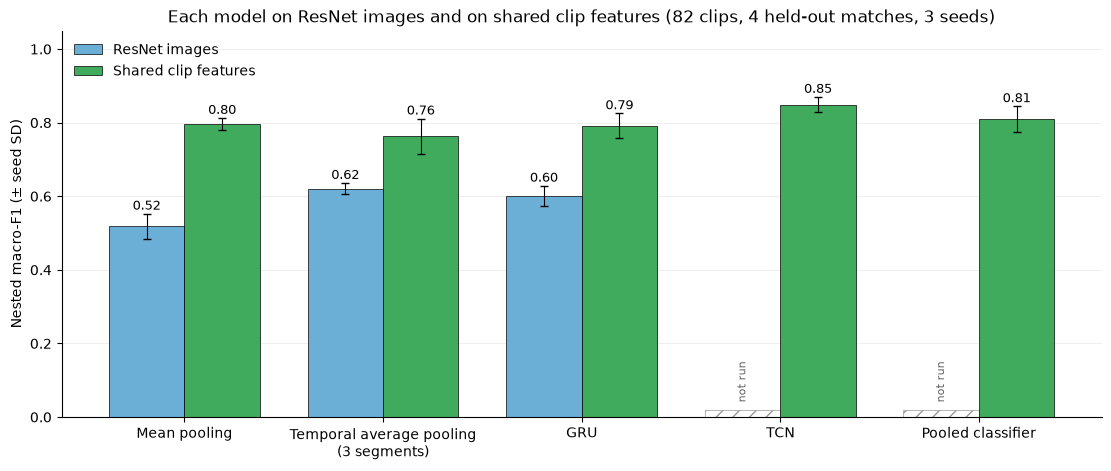

**With the same model, what changes when the input changes?** Mean pooling 0.518 → 0.796 (+0.278); Temporal average pooling (3 segments) 0.620 → 0.763 (+0.143); GRU 0.600 → 0.792 (+0.192). 3 of 3 models scored higher with shared clip features. The inputs are also sampled differently: image models see 16 evenly spaced frames per clip, while shared clip features have 5 rows per second (median 98 rows per clip), so the gain mixes richer content with denser sampling.

**With the same input, what changes when the model changes?** On shared clip features the TCN scored 0.849 ± 0.021, +0.040 against its pooled control (0.809 ± 0.035), which sees the same rows but pools them over time. The TCN led the control on 2 of 4 held-out matches (Furia vs Falcons, Aurora vs Vitality) and trailed on Spirit vs Falcons, MOUZ vs BetBoom. The gap is 1.1 times the larger seed SD (0.035). The control already receives elapsed time and route-history features (which map regions the Ts have reached so far), so the gap measures what the order of steps adds beyond those. The simpler models on shared clip features scored 0.763 to 0.796.

In [11]:
table = [[m] + [fmt(nested.get((m, i))) for i in INPUTS] for m in MODELS]
show_table(pd.DataFrame(table, columns=["Model (nested macro-F1)"] + INPUTS))
missing = [(m, i) for m in MODELS for i in INPUTS if (m, i) not in nested]
other_only = [(m, i) for m, i in missing if (m, i, "other-folds") in results]
say(
    f"{DASH} means no completed nested run. "
    + (
        "Only other-folds runs exist for "
        + "; ".join(
            "the " + " and ".join(m if m == "TCN" else m.lower() for m, j in other_only if j == i) + f" on {inp(i)}"
            for i in dict.fromkeys(i for _, i in other_only)
        )
        + " (Appendix A1); "
        if other_only else ""
    )
    + "the other dashes were not run."
)

fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
pair = {"ResNet images": "#6baed6", "Shared clip features": "#41ab5d"}
x = np.arange(len(MODELS))
for k, inputs in enumerate(pair):
    for xi, m in zip(x, MODELS):
        pos = xi + (k - 0.5) * 0.38
        r = nested.get((m, inputs))
        if r is None:
            ax.bar(pos, 0.02, 0.38, color="white", edgecolor="#999999", hatch="//", linewidth=0.5)
            ax.text(pos, 0.04, "not run", ha="center", va="bottom", fontsize=8, color="#666666", rotation=90)
            continue
        ax.bar(pos, r["mean"], 0.38, color=pair[inputs], edgecolor="black", linewidth=0.5, label=inputs if xi == 0 else None)
        ax.errorbar(pos, r["mean"], yerr=r["sd"], color="black", linewidth=0.8, capsize=3)
        ax.annotate(f"{r['mean']:.2f}", (pos, r["mean"] + r["sd"]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x, [m.replace(" (3 segments)", "\n(3 segments)") for m in MODELS])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Nested macro-F1 (± seed SD)")
ax.set_title(f"Each model on ResNet images and on shared clip features ({N_CLIPS} clips, {len(reference)} held-out matches, {N_SEEDS} seeds)")
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

# With the same model, the input changes.
input_lines = [
    f"{m} {nested[(m, 'ResNet images')]['mean']:.3f} → {nested[(m, 'Shared clip features')]['mean']:.3f} ({changes[m]:+.3f})"
    for m in both
]
higher = sum(changes[m] > 0 for m in both)
clip_rates = [rows_per_clip[c] for c in rows_per_clip]
say(
    "**With the same model, what changes when the input changes?** "
    + "; ".join(input_lines) + ". "
    + f"{higher} of {len(both)} models scored higher with shared clip features. The inputs are also sampled differently: "
    f"image models see {n_frames} evenly spaced frames per clip, while shared clip features have {rate:.0f} rows per second "
    f"(median {np.median(clip_rates):.0f} rows per clip), so the gain mixes richer content with denser sampling."
)

# With the same input, the model changes.
tcn, control = nested.get(("TCN", "Shared clip features")), nested.get(("Pooled classifier", "Shared clip features"))
if tcn and control:
    gap = tcn["mean"] - control["mean"]
    leads = [mt for mt in MATCHES if tcn["per_match"][mt] > control["per_match"][mt]]
    trails = [mt for mt in MATCHES if tcn["per_match"][mt] < control["per_match"][mt]]
    simple = [m for m in clip_models if m not in ("TCN", "Pooled classifier")]
    say(
        "**With the same input, what changes when the model changes?** On shared clip features the TCN scored "
        f"{fmt(tcn)}, {gap:+.3f} against its pooled control ({fmt(control)}), which sees the same rows but pools them over time. "
        f"The TCN led the control on {len(leads)} of {len(MATCHES)} held-out matches"
        + (f" ({', '.join(MATCH_NAMES[mt] for mt in leads)})" if leads else "")
        + (f" and trailed on {', '.join(MATCH_NAMES[mt] for mt in trails)}" if trails else "")
        + f". The gap is {gap / max(tcn['sd'], control['sd']):.1f} times the larger seed SD ({max(tcn['sd'], control['sd']):.3f}). "
        "The control already receives elapsed time and route-history features (which map regions the Ts have reached so far), "
        "so the gap measures what the order of steps adds beyond those."
        + (
            f" The simpler models on shared clip features scored {min(clip_models[m]['mean'] for m in simple):.3f} to "
            f"{max(clip_models[m]['mean'] for m in simple):.3f}."
            if simple else ""
        )
    )

### F1 by tactic: which tactics are hardest?

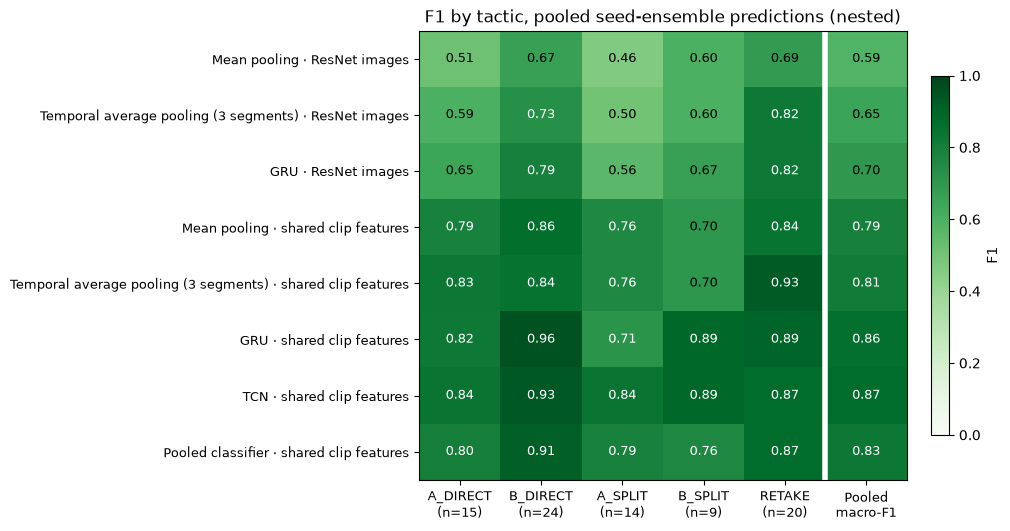

How this is computed: every clip is predicted by the model that held out its match, with class probabilities averaged over the 3 seeds, and all 82 clips are scored together. The pooled macro-F1 column is the mean of the 5 class F1 scores on these pooled predictions, so it can differ from the headline nested macro-F1, which is averaged per held-out match and seed (here by up to 0.097).

**Answer.** Averaged over the 8 rows, A_SPLIT is the hardest class (mean F1 0.67) and RETAKE the easiest (0.84). On shared clip features alone, the hardest class is A_SPLIT.

In [12]:
rows = [(m, i) for i in INPUTS for m in MODELS if (m, i) in nested]
values = np.array([[nested[k]["pooled_f1"][c] for c in CLASSES] + [nested[k]["pooled_macro"]] for k in rows])
fig, ax = plt.subplots(figsize=(10, 0.45 * len(rows) + 1.6), layout="constrained")
image = ax.imshow(values, cmap="Greens", vmin=0, vmax=1, aspect="auto")
for r in range(values.shape[0]):
    for c in range(values.shape[1]):
        ax.text(c, r, f"{values[r, c]:.2f}", ha="center", va="center", fontsize=9, color="white" if values[r, c] > 0.7 else "black")
ax.axvline(len(CLASSES) - 0.5, color="white", linewidth=4)
ax.set_xticks(range(len(CLASSES) + 1), [f"{c}\n(n={totals[c]})" for c in CLASSES] + ["Pooled\nmacro-F1"], fontsize=9)
ax.set_yticks(range(len(rows)), [f"{m} · {inp(i)}" for m, i in rows], fontsize=9)
ax.set_title("F1 by tactic, pooled seed-ensemble predictions (nested)")
fig.colorbar(image, ax=ax, shrink=0.8, label="F1")
plt.show()
class_mean = {c: float(np.mean([nested[k]["pooled_f1"][c] for k in rows])) for c in CLASSES}
hardest, easiest = min(class_mean, key=class_mean.get), max(class_mean, key=class_mean.get)
clip_rows_keys = [k for k in rows if k[1] == "Shared clip features"]
clip_hardest = min(CLASSES, key=lambda c: np.mean([nested[k]["pooled_f1"][c] for k in clip_rows_keys])) if clip_rows_keys else None
gaps = [abs(nested[k]["pooled_macro"] - nested[k]["mean"]) for k in rows]
say(
    f"How this is computed: every clip is predicted by the model that held out its match, with class probabilities "
    f"averaged over the {N_SEEDS} seeds, and all {N_CLIPS} clips are scored together. The pooled macro-F1 column is the mean of the "
    f"{len(CLASSES)} class F1 scores on these pooled predictions, so it can differ from the headline nested macro-F1, "
    f"which is averaged per held-out match and seed (here by up to {max(gaps):.3f}).\n\n"
    f"**Answer.** Averaged over the {len(rows)} rows, {hardest} is the hardest class (mean F1 {class_mean[hardest]:.2f}) and "
    f"{easiest} the easiest ({class_mean[easiest]:.2f})."
    + (f" On shared clip features alone, the hardest class is {clip_hardest}." if clip_hardest else "")
)

## 5. Where does the selected model go wrong?

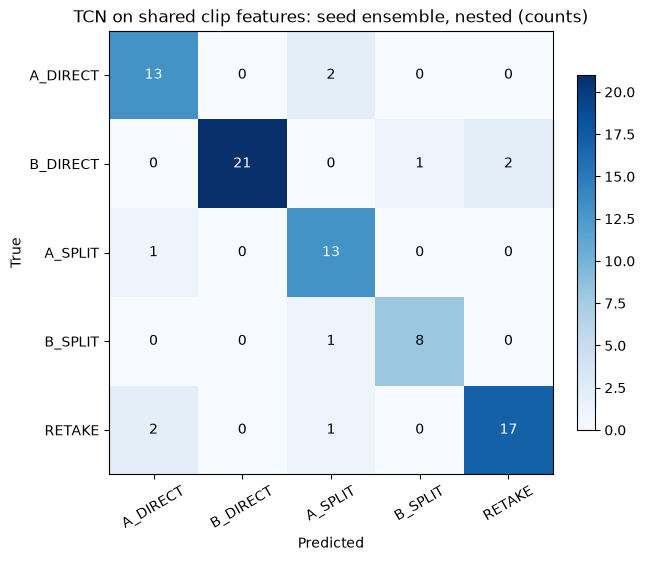

Counts from the seed ensemble: each clip's class probabilities are averaged over the 3 seeds of the model that held out its match. Correct A/B/retake group: **76 of 82**. Split vs direct right: **55 of 59** attacks whose site was right. Seed-ensemble accuracy: 0.878.

In [13]:
model, inputs = best_key
selected = nested[best_key]
matrix = selected["confusion"]
fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
image = ax.imshow(matrix, cmap="Blues")
for i in range(5):
    for j in range(5):
        ax.text(j, i, matrix[i, j], ha="center", va="center", color="white" if matrix[i, j] > matrix.max() / 2 else "black")
ax.set_xticks(range(5), CLASSES, rotation=30)
ax.set_yticks(range(5), CLASSES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"{model} on {inp(inputs)}: seed ensemble, nested (counts)")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()
group = sum(matrix[i, j] for i, t in enumerate(CLASSES) for j, p in enumerate(CLASSES) if SITE[t] == SITE[p])
site_ab = [(i, j) for i, t in enumerate(CLASSES) for j, p in enumerate(CLASSES) if SITE[t] == SITE[p] and SITE[t] != "RETAKE"]
given = sum(matrix[i, j] for i, j in site_ab)
exact = sum(matrix[i, i] for i, t in enumerate(CLASSES) if SITE[t] != "RETAKE")
say(
    f"Counts from the seed ensemble: each clip's class probabilities are averaged over the {N_SEEDS} seeds of the model that "
    f"held out its match. Correct A/B/retake group: **{group} of {matrix.sum()}**. Split vs direct right: **{exact} of {given}** "
    f"attacks whose site was right. Seed-ensemble accuracy: {np.trace(matrix) / matrix.sum():.3f}."
)

In [14]:
clip_rows = selected["clip_rows"]
errors = [r for r in clip_rows if int(r["probs"].argmax()) != r["truth"]]
errors.sort(key=lambda r: -r["probs"].max())
TOP = 5
show_table(
    pd.DataFrame(
        [
            [r["clip_id"].split(".")[-1], MATCH_NAMES[match_of(r["clip_id"])], CLASSES[r["truth"]], CLASSES[int(r["probs"].argmax())], float(r["probs"].max())]
            for r in errors[:TOP]
        ],
        columns=["Clip", "Match", "True", "Predicted", "Probability of prediction"],
    )
)


def kind(r):
    t, p = CLASSES[r["truth"]], CLASSES[int(r["probs"].argmax())]
    if (t == "RETAKE") != (p == "RETAKE"):
        return "attack/retake"
    return "split/direct" if SITE[t] == SITE[p] else "wrong site"


kinds = {k: [r for r in errors if kind(r) == k] for k in ("split/direct", "attack/retake", "wrong site")}


def pairs_of(rs):
    counts = {}
    for r in rs:
        key = f"{CLASSES[r['truth']]} → {CLASSES[int(r['probs'].argmax())]}"
        counts[key] = counts.get(key, 0) + 1
    return ", ".join(f"{k} ×{n}" for k, n in sorted(counts.items(), key=lambda kv: -kv[1]))


per_match = {mt: sum(match_of(r["clip_id"]) == mt for r in errors) for mt in MATCHES}
worst = max(per_match, key=per_match.get)
confident = sum(r["probs"].max() >= 0.5 for r in errors)
hypotheses = []
if kinds["split/direct"]:
    hypotheses.append("split/direct mix-ups may come from a second group that is small, late or hard to see on the minimap")
if kinds["attack/retake"]:
    hypotheses.append("attack/retake mix-ups may come from clip boundaries, for example a retake clip that still contains the attack before the plant")
if kinds["wrong site"]:
    hypotheses.append("wrong-site errors may come from a fake or a late rotation within the clip")
say(
    f"**Answer.** The table shows the {min(TOP, len(errors))} most confident of {len(errors)} errors; {confident} errors had a predicted "
    f"probability of at least 0.5. Of the {len(errors)} errors, {len(kinds['split/direct'])} keep the site but confuse split and "
    f"direct ({pairs_of(kinds['split/direct']) or 'none'}), {len(kinds['attack/retake'])} confuse an attack with a retake "
    f"({pairs_of(kinds['attack/retake']) or 'none'}), and {len(kinds['wrong site'])} pick the wrong site for an attack "
    f"({pairs_of(kinds['wrong site']) or 'none'}). {MATCH_NAMES[worst]} has the most errors ({per_match[worst]} of its "
    f"{len(reference[worst])} clips).\n\n"
    + ("**Hypotheses** (the footage of these clips was not reviewed): " + "; ".join(hypotheses) + "." if hypotheses else "")
)

Clip,Match,True,Predicted,Probability of prediction
s006,Spirit vs Falcons,B_DIRECT,RETAKE,0.876
s014,MOUZ vs BetBoom,RETAKE,A_DIRECT,0.795
s011,Spirit vs Falcons,B_DIRECT,B_SPLIT,0.713
s012,MOUZ vs BetBoom,A_DIRECT,A_SPLIT,0.698
s011,Furia vs Falcons,RETAKE,A_SPLIT,0.644


**Answer.** The table shows the 5 most confident of 10 errors; 7 errors had a predicted probability of at least 0.5. Of the 10 errors, 4 keep the site but confuse split and direct (A_DIRECT → A_SPLIT ×2, B_DIRECT → B_SPLIT ×1, A_SPLIT → A_DIRECT ×1), 5 confuse an attack with a retake (B_DIRECT → RETAKE ×2, RETAKE → A_DIRECT ×2, RETAKE → A_SPLIT ×1), and 1 pick the wrong site for an attack (B_SPLIT → A_SPLIT ×1). Spirit vs Falcons has the most errors (5 of its 21 clips).

**Hypotheses** (the footage of these clips was not reviewed): split/direct mix-ups may come from a second group that is small, late or hard to see on the minimap; attack/retake mix-ups may come from clip boundaries, for example a retake clip that still contains the attack before the plant; wrong-site errors may come from a fake or a late rotation within the clip.

## 6. What limits these results, and which model do we choose?

In [15]:
gaps = []
for m in MODELS:
    a, b = results.get((m, "ResNet images", "nested")), results.get((m, "ResNet images", "other-folds"))
    if a and b:
        gaps.append((m, b["mean"] - a["mean"]))
for version, d in gru_versions.items():
    if version != "compact_pooled" and d["nested"] and d["other-folds"]:
        gaps.append((GRU_NAMES[version], d["other-folds"]["mean"] - d["nested"]["mean"]))
spreads = {k: max(r["per_match"].values()) - min(r["per_match"].values()) for k, r in nested.items()}
higher = sum(g > 0 for _, g in gaps)
say(
    f"- **Other-folds epoch selection is optimistic for {'most' if higher > len(gaps) / 2 else 'some'} image models.** It scored "
    f"{higher} of {len(gaps)} image models higher than nested selection (other-folds minus nested: "
    f"{min(g for _, g in gaps):+.3f} to {max(g for _, g in gaps):+.3f}; Appendix A1), so nested scores are the main estimate.\n"
    "- **Map regions were adjusted after looking at training labels** ([shared clip features](../docs/clip-data.md#map-regions)), "
    "so every score on shared clip features may be optimistic.\n"
    "- **The detector's empty-map background is built from the same match's frames** (pixels only, no labels), including "
    "the held-out match.\n"
    "- **Clip boundaries were cut by hand**, so where a clip starts and ends could hint at its class; this was not tested.\n"
    f"- **Only {len(MATCHES)} development matches, with a large spread between them:** within one model and input, held-out "
    f"matches differ by up to {max(spreads.values()):.3f} macro-F1 (Appendix A2).\n"
    "- **Test history.** This notebook uses development matches only. Earlier TCN experiments evaluated the test matches separately."
)

- **Other-folds epoch selection is optimistic for most image models.** It scored 4 of 5 image models higher than nested selection (other-folds minus nested: -0.006 to +0.081; Appendix A1), so nested scores are the main estimate.
- **Map regions were adjusted after looking at training labels** ([shared clip features](../docs/clip-data.md#map-regions)), so every score on shared clip features may be optimistic.
- **The detector's empty-map background is built from the same match's frames** (pixels only, no labels), including the held-out match.
- **Clip boundaries were cut by hand**, so where a clip starts and ends could hint at its class; this was not tested.
- **Only 4 development matches, with a large spread between them:** within one model and input, held-out matches differ by up to 0.257 macro-F1 (Appendix A2).
- **Test history.** This notebook uses development matches only. Earlier TCN experiments evaluated the test matches separately.

In [16]:
best_model, best_input = best_key
control_key = ("Pooled classifier", best_input) if best_model == "TCN" else None
text = (
    f"**Model decision.** Among completed nested runs we prefer the **{best_model} on {inp(best_input)}** "
    f"(nested macro-F1 {fmt(nested[best_key])})."
)
if control_key and control_key in nested:
    c = nested[control_key]
    margin = nested[best_key]["mean"] - c["mean"]
    leads = sum(nested[best_key]["per_match"][mt] > c["per_match"][mt] for mt in MATCHES)
    text += (
        f" Its margin over the same-input pooled control is {margin:+.3f}, and it led the control on {leads} of "
        f"{len(MATCHES)} held-out matches. "
    )
    spread = spreads[best_key]
    text += (
        f"That margin is small next to the {spread:.3f} spread between its own held-out matches"
        if spread > margin
        else f"Its own held-out matches differ by {spread:.3f}"
    )
    text += (
        f", and with only {len(MATCHES)} development matches and map regions drawn with knowledge of the training labels, "
        "it is an estimate rather than a settled ranking."
    )
say(text)

**Model decision.** Among completed nested runs we prefer the **TCN on shared clip features** (nested macro-F1 0.849 ± 0.021). Its margin over the same-input pooled control is +0.040, and it led the control on 2 of 4 held-out matches. That margin is small next to the 0.257 spread between its own held-out matches, and with only 4 development matches and map regions drawn with knowledge of the training labels, it is an estimate rather than a settled ranking.

## Appendix

### A1. How optimistic is other-folds epoch selection?

Other-folds epoch selection scores each held-out match at the epoch that was best on the other held-out matches, whose models were trained on the scored match. Nested selection never uses the scored match.

In [17]:
rows = []
for i in INPUTS:
    for m in MODELS:
        a, b = results.get((m, i, "nested")), results.get((m, i, "other-folds"))
        if a or b:
            rows.append([m, i, fmt(a), fmt(b), b["mean"] - a["mean"] if a and b else DASH])
for version in ("laststate", "compact_laststate"):
    a, b = gru_versions[version]["nested"], gru_versions[version]["other-folds"]
    if a or b:
        rows.append([GRU_NAMES[version], "ResNet images", fmt(a), fmt(b), b["mean"] - a["mean"] if a and b else DASH])
show_table(pd.DataFrame(rows, columns=["Model", "Input", "Nested", "Other-folds", "Other-folds − nested"]))
diffs = [r[4] for r in rows if not isinstance(r[4], str)]
say(
    f"**Answer.** Other-folds minus nested ranges from {min(diffs):+.3f} to {max(diffs):+.3f} across the {len(diffs)} pairs "
    f"with both; {sum(d > 0 for d in diffs)} of {len(diffs)} are positive."
)

Model,Input,Nested,Other-folds,Other-folds − nested
Mean pooling,ResNet images,0.518 ± 0.034,0.584 ± 0.016,0.066
Temporal average pooling (3 segments),ResNet images,0.620 ± 0.015,0.650 ± 0.013,0.030
GRU,ResNet images,0.600 ± 0.028,0.681 ± 0.049,0.081
TCN,Detector features,—,0.679 ± 0.016,—
Pooled classifier,Detector features,—,0.645 ± 0.018,—
Mean pooling,Shared clip features,0.796 ± 0.016,0.790 ± 0.022,-0.007
Temporal average pooling (3 segments),Shared clip features,0.763 ± 0.048,0.775 ± 0.018,0.012
GRU,Shared clip features,0.792 ± 0.033,0.809 ± 0.034,0.017
TCN,Shared clip features,0.849 ± 0.021,0.834 ± 0.026,-0.015
Pooled classifier,Shared clip features,0.809 ± 0.035,0.823 ± 0.027,0.014


**Answer.** Other-folds minus nested ranges from -0.015 to +0.081 across the 10 pairs with both; 7 of 10 are positive.

### A2. How much do the held-out matches differ?

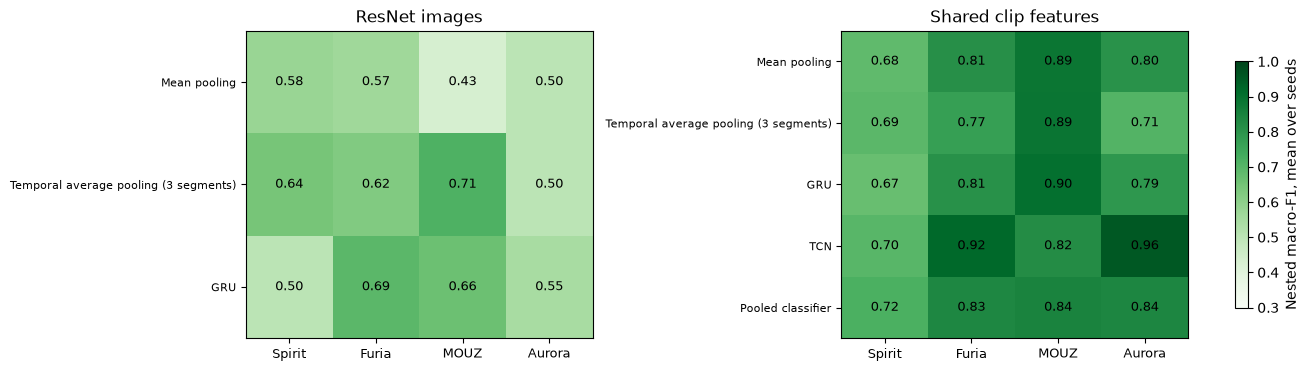

**Answer.** Held-out matches are named by their first team. The lowest match on average: ResNet images: Aurora vs Vitality; shared clip features: Spirit vs Falcons. Within one model and input, matches differ by up to 0.257.

In [18]:
panels = [(i, [m for m in MODELS if (m, i) in nested]) for i in ("ResNet images", "Shared clip features")]
panels = [(i, ms) for i, ms in panels if ms]
fig, axes = plt.subplots(1, len(panels), figsize=(13, 3.6), layout="constrained")
for ax, (inputs, ms) in zip(np.atleast_1d(axes), panels):
    values = np.array([[nested[(m, inputs)]["per_match"][mt] for mt in MATCHES] for m in ms])
    image = ax.imshow(values, cmap="Greens", vmin=0.3, vmax=1.0, aspect="auto")
    for r in range(len(ms)):
        for c in range(len(MATCHES)):
            ax.text(c, r, f"{values[r, c]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(MATCHES)), [MATCH_NAMES[mt].split(" vs ")[0] for mt in MATCHES], fontsize=9)
    ax.set_yticks(range(len(ms)), ms, fontsize=8)
    ax.set_title(inputs)
fig.colorbar(image, ax=axes, shrink=0.8, label="Nested macro-F1, mean over seeds")
plt.show()
hardest_match = {i: min(MATCHES, key=lambda mt: np.mean([nested[(m, i)]["per_match"][mt] for m in ms])) for i, ms in panels}
say(
    "**Answer.** Held-out matches are named by their first team. The lowest match on average: "
    + "; ".join(f"{inp(i)}: {MATCH_NAMES[mt]}" for i, mt in hardest_match.items())
    + f". Within one model and input, matches differ by up to {max(spreads.values()):.3f}."
)

### A3. Do the procedures learn anything from shuffled labels?

Each check refits the whole procedure with labels shuffled within each match and scores against the shuffled labels. A sound procedure lands near chance.

In [19]:
checks = []
for key, model, name, inputs in (
    ("img_nested", "mean", "Mean pooling", "ResNet images"),
    ("img_nested", "thirds", "Temporal average pooling (3 segments)", "ResNet images"),
    ("img_other", "mean", "Mean pooling", "ResNet images"),
    ("img_other", "thirds", "Temporal average pooling (3 segments)", "ResNet images"),
    ("img_other", "gru", GRU_NAMES["laststate"], "ResNet images"),
    ("random_segments", "random-thirds", "Random-segment control", "ResNet images"),
    ("gru_shuffled", "gru", "GRU", "ResNet images"),
):
    folder = runs.get(key)
    path = folder / model / "shuffled-labels.json" if folder else None
    if path and path.is_file():
        check = json.loads(path.read_text(encoding="utf-8"))
        values = [p["macro_f1"] for p in check["permutations"]]
        rule = json.loads((folder / model / "config.json").read_text(encoding="utf-8"))["epoch_mode"]
        checks.append([name, inputs, rule, check["real"]["macro_f1"], float(np.mean(values)), max(values), f"{check['at_least_real']} of {check['count']}"])
folder = runs.get("tcn_clip_shuffled")
real = results.get(("TCN", "Shared clip features", "other-folds"))
if folder and real:
    values = [json.loads(p.read_text(encoding="utf-8"))["models"]["tcn"]["cross_fold_macro_f1"] for p in sorted(folder.glob("permutation-*.json"))]
    checks.append(["TCN", "Shared clip features", "other-folds", real["mean"], float(np.mean(values)), max(values), f"{sum(v >= real['mean'] for v in values)} of {len(values)}"])
show_table(pd.DataFrame(checks, columns=["Model", "Input", "Epoch selection", "Real macro-F1", "Shuffled: mean", "Shuffled: highest", "Shuffled at or above real"]))
checked = {(c[0], c[1]) for c in checks}
none = list(dict.fromkeys(f"{m} on {inp(i)}" for (m, i, _) in results if (m, i) not in checked))
say(
    f"**Answer.** No shuffled refit reached its real score in {sum(c[6].startswith('0 of') for c in checks)} of {len(checks)} checks. "
    "Without a shuffled-label check: " + "; ".join(none) + "."
)

Model,Input,Epoch selection,Real macro-F1,Shuffled: mean,Shuffled: highest,Shuffled at or above real
Mean pooling,ResNet images,nested,0.518,0.146,0.281,0 of 20
Temporal average pooling (3 segments),ResNet images,nested,0.620,0.155,0.271,0 of 20
Mean pooling,ResNet images,other-folds,0.584,0.179,0.314,0 of 20
Temporal average pooling (3 segments),ResNet images,other-folds,0.650,0.168,0.295,0 of 20
Last-state GRU,ResNet images,other-folds,0.338,0.180,0.278,0 of 20
Random-segment control,ResNet images,nested,0.526,0.142,0.276,0 of 20
GRU,ResNet images,other-folds,0.681,0.176,0.264,0 of 20
TCN,Shared clip features,other-folds,0.834,0.175,0.230,0 of 20


**Answer.** No shuffled refit reached its real score in 8 of 8 checks. Without a shuffled-label check: Mean pooling on shared clip features; Temporal average pooling (3 segments) on shared clip features; GRU on shared clip features; Pooled classifier on shared clip features; TCN on detector features; Pooled classifier on detector features.

### A4. Does time order matter to temporal average pooling?

The random-segment control uses the same three segments and classifier as temporal average pooling, but puts each clip's frames into the segments at random, which removes the time order (ResNet images, nested).

In [20]:
t = results.get(("Temporal average pooling (3 segments)", "ResNet images", "nested"))
if t and random_segments:
    keys = sorted(t["pairs"])
    ahead = sum(t["pairs"][k] > random_segments["pairs"][k] for k in keys)
    show_table(
        pd.DataFrame(
            [["Temporal average pooling (3 segments)", fmt(t)], ["Random-segment control", fmt(random_segments)]],
            columns=["Model", "Nested macro-F1"],
        )
    )
    say(
        f"**Answer.** Temporal average pooling is ahead of the control in {ahead} of {len(keys)} match-and-seed pairs, "
        f"by {t['mean'] - random_segments['mean']:+.3f} on average."
    )
else:
    say(f"{DASH} Temporal average pooling or the random-segment control was not found.")

Model,Nested macro-F1
Temporal average pooling (3 segments),0.620 ± 0.015
Random-segment control,0.526 ± 0.012


**Answer.** Temporal average pooling is ahead of the control in 11 of 12 match-and-seed pairs, by +0.094 on average.

### A5. What settings did each model use?

In [21]:
def temporal_row(family, inputs, r):
    s, t = r["config"]["settings"], r["config"].get("temporal", {})
    return [
        family,
        inputs,
        "AdamW",
        s["learning_rate"],
        s["weight_decay"],
        "full batch",
        f"up to {s['epochs']}, stop after {s['patience']} without gain",
        t.get("dropout", 0.0) if "projection" in t else 0.0,
        0.0,
        "none",
        "on" if s.get("class_weights", True) else "off",
    ]


def tcn_row(family, inputs, r):
    c = r["config"]
    augmentation = f"position jitter {c['jitter']}, {c['drop']:.0%} detections dropped" if c["input"] == "detections" else "none"
    return [
        family,
        inputs,
        f"AdamW, warm-up {c['warmup_epochs']} epochs",
        c["lr"],
        c["weight_decay"],
        c["batch"],
        f"up to {c['epochs']}, checked every {c['eval_every']}",
        c["dropout"],
        c["label_smoothing"],
        augmentation,
        "on",
    ]


rows = []
for family, key in (
    ("Mean pooling and temporal average pooling", ("Mean pooling", "Shared clip features", "nested")),
    ("GRU", ("GRU", "Shared clip features", "nested")),
):
    if key in results:
        rows.append(temporal_row(family, "ResNet images, shared clip features", results[key]))
for family, key in (
    ("TCN and pooled classifier", ("TCN", "Detector features", "other-folds")),
    ("TCN and pooled classifier", ("TCN", "Shared clip features", "nested")),
):
    if key in results:
        rows.append(tcn_row(family, key[1], results[key]))
show_table(
    pd.DataFrame(
        rows,
        columns=["Model family", "Input", "Optimiser", "Learning rate", "Weight decay", "Batch size", "Epochs", "Dropout", "Label smoothing", "Augmentation", "Class weighting"],
    )
)
KEYS = ("learning_rate", "weight_decay", "epochs", "patience", "class_weights")
same = all(
    results[(m, "ResNet images", "nested")]["config"]["settings"].get(k, True) == results[(m, "Shared clip features", "nested")]["config"]["settings"].get(k, True)
    for m in ("Mean pooling", "Temporal average pooling (3 segments)", "GRU")
    if (m, "ResNet images", "nested") in results and (m, "Shared clip features", "nested") in results
    for k in KEYS
)
augmented = [f"{r[0]} on {inp(r[1])}" for r in rows if r[9] != "none"]
say(
    "Values are read from each run's saved configuration. "
    + ("The image runs of mean pooling, temporal average pooling and the GRU use the same settings as their shared-clip-feature runs. " if same else "Image and shared-clip-feature runs differ in some settings; see their config.json files. ")
    + (f"Only the {'; '.join(augmented)} {'use' if len(augmented) > 1 or ' and ' in augmented[0] else 'uses'} augmentation." if augmented else "No model uses augmentation.")
)

Model family,Input,Optimiser,Learning rate,Weight decay,Batch size,Epochs,Dropout,Label smoothing,Augmentation,Class weighting
Mean pooling and temporal average pooling,"ResNet images, shared clip features",AdamW,0.010,0.001,full batch,"up to 200, stop after 30 without gain",0.000,0.000,none,on
GRU,"ResNet images, shared clip features",AdamW,0.010,0.001,full batch,"up to 200, stop after 30 without gain",0.300,0.000,none,on
TCN and pooled classifier,Detector features,"AdamW, warm-up 5 epochs",0.001,0.010,8,"up to 150, checked every 10",0.200,0.050,"position jitter 0.005, 5% detections dropped",on
TCN and pooled classifier,Shared clip features,"AdamW, warm-up 5 epochs",0.001,0.010,8,"up to 150, checked every 10",0.200,0.050,none,on


Values are read from each run's saved configuration. The image runs of mean pooling, temporal average pooling and the GRU use the same settings as their shared-clip-feature runs. Only the TCN and pooled classifier on detector features use augmentation.

### A6. What were the three GRU designs?

In [22]:
rows = []
for version, d in gru_versions.items():
    r = d["nested"] or d["other-folds"]
    if r is None:
        rows.append([GRU_NAMES[version]] + [DASH] * 7)
        continue
    t = r["config"]["temporal"]
    rows.append(
        [
            GRU_NAMES[version],
            t["projection"],
            t["hidden"],
            t.get("dropout", 0.0),
            "mean and max over real frames" if t.get("readout", "last") == "mean-max" else "last state",
            int(r["config"]["trainable_parameters"]),
            fmt(d["nested"]),
            fmt(d["other-folds"]),
        ]
    )
show_table(pd.DataFrame(rows, columns=["GRU design (ResNet images)", "Frame projection", "Memory size", "Dropout", "Readout", "Trainable weights", "Nested macro-F1", "Other-folds macro-F1"]))
done = {v: d["nested"] for v, d in gru_versions.items() if d["nested"]}
say(
    "Each design was fixed before its score was seen; the Compact pooled GRU was selected and is \"GRU\" in section 4. "
    + (f"The largest seed SD among the nested runs is {max(r['sd'] for r in done.values()):.3f}." if done else "")
)

GRU design (ResNet images),Frame projection,Memory size,Dropout,Readout,Trainable weights,Nested macro-F1,Other-folds macro-F1
Last-state GRU,32,32,0.000,last state,23109,0.345 ± 0.008,0.338 ± 0.011
Compact last-state GRU,8,16,0.300,last state,5533,0.327 ± 0.004,0.354 ± 0.020
Compact pooled GRU,8,16,0.300,mean and max over real frames,5613,0.600 ± 0.028,0.681 ± 0.049


Each design was fixed before its score was seen; the Compact pooled GRU was selected and is "GRU" in section 4. The largest seed SD among the nested runs is 0.028.

### A7. How can these results be reproduced?

**Kernel.** Use the project's `.venv` (setup in the [README](../README.md)) as the notebook kernel and run every cell from top to bottom. The notebook only reads run folders: it trains nothing, writes nothing and never reads the test matches.

**Run folders.** They are not in Git; they are shared as a ZIP to extract into `runs/`. The first code cell lists every folder the notebook reads. The check below prints which were found, and the loading cell stops if any result uses other clips, held-out matches, seeds or epoch selection than it is labelled with, or if a recomputed score differs from the run's saved summary.

In [23]:
import platform
import sys
from importlib.metadata import PackageNotFoundError, version


def installed(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return "not installed"


for name, folder in runs.items():
    print(f"{'found  ' if folder else 'MISSING'}  {name:<33} {folder.relative_to(ROOT).as_posix() if folder else RUNS[name]}")
print(
    f"\nLoaded {len(everything)} results. All use the same {N_CLIPS} clips, the same {len(reference)} held-out matches, "
    f"seeds 0-{N_SEEDS - 1} and the epoch selection they are labelled with."
)
print(
    f"Checked {len(VERIFIED)} recomputed values ({len({label for label, _ in VERIFIED})} results) against the runs' saved "
    f"summary files: all agree within {TOLERANCE:g}."
)
executable = Path(sys.executable)
try:
    executable = executable.relative_to(ROOT).as_posix()
except ValueError:
    executable = executable.name
saved = results[("Mean pooling", "ResNet images", "nested")]["config"]
print(
    f"\nNotebook kernel: Python {platform.python_version()} ({executable}); numpy {installed('numpy')}, "
    f"pandas {installed('pandas')}, matplotlib {installed('matplotlib')}, torch {installed('torch')}."
)
print(
    f"Training runs (from config.json): Python {saved.get('python', '?')}; "
    + ", ".join(f"{k} {v}" for k, v in saved.get("versions", {}).items())
    + f"; device {saved.get('device', '?')}."
)

found    img_nested                        runs/tactic-temporal-20261116
found    img_gru_pooled_nested             runs/tactic-gru-nested-20261120
found    img_gru_laststate_nested          runs/tactic-gru-first-nested-20261120
found    img_gru_compact_laststate_nested  runs/tactic-gru-middle-nested-20261120
found    img_thirds_unweighted             runs/tactic-thirds-unweighted-nested-20261120
found    img_other                         runs/tactic-temporal-other-folds-20261119
found    img_gru_compact_laststate_other   runs/tactic-gru-small-other-folds-20261119
found    img_gru_pooled_other              runs/tactic-gru-pooled-other-folds-20261119
found    clip_nested                       runs/tactic-clipdata-nested-20261120
found    clip_other                        runs/tactic-clipdata-other-folds-20261120
found    tcn_clip_nested                   runs/tactic-tcn-clipdata-nested-20261120
found    tcn_clip_other                    runs/tactic-tcn-clipdata-repro-20261119
found    t

**Repeat the experiments.** Data: the 2026-11-16 export with the uncertain clip left out (`--exclude-uncertain`), and shared clip features built with regions `mirage-spectator-v1`. Use the train-only copies so the test matches are never read: `data/processed/datasets/2026-11-16-train-only` (empty test manifest) and `data/processed/clip-data-2026-11-16-train-only` (train `.npz` files, `channels.json`, and an `index.csv` with only train rows). Every output folder must be new. Run from the repository root:

```powershell
$M = "data/processed/datasets/2026-11-16-train-only/train/manifest.csv"
$D = "data/processed/datasets/2026-11-16-train-only"
$C = "data/processed/clip-data-2026-11-16-train-only"
$F = "runs/tactic-temporal-20261116/frame-features.pt"   # ResNet frame features from the first image run
# ResNet images, nested: mean pooling and temporal average pooling (with 20 shuffled-label refits)
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-temporal-<new> --exclude-uncertain --shuffles 20
# GRU designs, nested: Compact pooled GRU (default), Last-state GRU, Compact last-state GRU
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-nested-<new> --exclude-uncertain --models gru --features $F
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-laststate-nested-<new> --exclude-uncertain --models gru --features $F --gru-projection 32 --gru-hidden 32 --gru-dropout 0 --gru-readout last
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-compact-laststate-nested-<new> --exclude-uncertain --models gru --features $F --gru-readout last
# Class weights off
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-thirds-unweighted-nested-<new> --exclude-uncertain --models thirds --features $F --no-class-weights
# Random-segment control
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-temporal-random-thirds-<new> --exclude-uncertain --models random-thirds --features $F --shuffles 20
# Other-folds epoch selection on images (for each GRU design, add --models gru and its GRU options)
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-temporal-other-folds-<new> --exclude-uncertain --features $F --epoch-mode other-folds --shuffles 20
# Shared clip features: mean pooling, temporal average pooling and the GRU, nested then other-folds
bash scripts/clipdata_temporal_20261120.sh
# Shared clip features: TCN and pooled classifier, nested
python scripts/nested_tcn.py --dataset $D --clip-data $C --output runs/tactic-tcn-clipdata-nested-<new> --models tcn control
# Shared clip features: TCN and pooled classifier, other-folds (train-tactics cross-validation)
python -m stratscout train-tactics --dataset $D --clip-data $C --output runs/tactic-tcn-clipdata-<new> --exclude-uncertain --seeds 3
# Detector features: TCN and pooled classifier, other-folds
python -m stratscout train-tactics --dataset $D --output runs/tactic-tcn-<new> --exclude-uncertain --seeds 3
# Shuffled labels: GRU (other-folds) and the TCN on shared clip features
python -m stratscout tactic-temporal --manifest $M --output runs/tactic-gru-shuffled-other-folds-<new> --exclude-uncertain --models gru --features $F --epoch-mode other-folds --shuffles 20
python scripts/shuffle_tcn.py --dataset $D --clip-data $C --output runs/tactic-tcn-clipdata-shuffled-<new> --models tcn --start 0 --count 20
```